# Análisis del Comportamiento de una Aplicación bajo Diferentes Escenarios de Despliegue

**Curso:** Principios y prácticas de Desarrollo de Software Orientado a Objetos
**Proyecto final** · Docker Compose · Kubernetes (K3s) · JMeter

**Integrantes:** Laura Ballesteros · Nikolas Pedrozo · Gabriel Garcia

---

## 1. Introducción

En este proyecto se despliega una misma aplicación backend (una **API REST de reservas de un cine** escrita en Java con Spring Boot y PostgreSQL) en distintos escenarios:

| Fase | Escenario | Réplicas de la API |
|---|---|---|
| 1 | Docker Compose en una sola máquina | 1 |
| 2 | Kubernetes (K3s) con **1 nodo** | 1, 2, 3 |
| 3 | Kubernetes (K3s) con **2 nodos** | 1, 2, 3 |
| 4 | Kubernetes (K3s) con **3 nodos** | 1, 2, 3 |

En cada escenario se genera carga con **Apache JMeter** desde una máquina distinta y se miden dos métricas:

* **Tiempo medio de respuesta** (ms): cuánto tarda en promedio la API en responder una petición.
* **Throughput** (peticiones/segundo): cuántas peticiones atiende la API por segundo.

### Objetivo general
Analizar cómo el entorno de despliegue, el número de **réplicas** y el número de **nodos** afectan el rendimiento de la aplicación, con énfasis en el **escalado horizontal**.

### Objetivos específicos
1. Desplegar la aplicación con Docker Compose en una máquina.
2. Desplegar la misma aplicación en Kubernetes con 1, 2 y 3 nodos, variando las réplicas (1, 2, 3).
3. Generar carga con JMeter (10, 50, 100 y 200 usuarios concurrentes) y registrar las métricas.
4. Comparar los escenarios, identificar tendencias y cuellos de botella.
5. Formular conclusiones y recomendaciones.

## 2. Descripción de la aplicación

**Cine API** es un backend REST construido con **Spring Boot 3 (Java 17)**, **Spring Data JPA / Hibernate** y **PostgreSQL 16**. Permite consultar la cartelera, ver el mapa de sillas de cada función y reservar o cancelar sillas.

### 2.1 Modelo de datos (11.210 registros)

| Tabla | Registros | Descripción |
|---|---|---|
| `peliculas` | 200 | título, género, duración, clasificación, año |
| `salas` | 10 | nombre, número de filas (A, B, C…) y sillas por fila |
| `funciones` | 1.000 | película + sala + fecha/hora + precio |
| `reservas` | 10.000 | una silla (fila, número) de una función reservada por un cliente |

Los datos se generan con `db/init.sql` (usa `generate_series` y `setseed`, por lo que **siempre son los mismos** y las pruebas son repetibles).

**Regla de negocio:** una silla no puede reservarse dos veces en la misma función. El servicio lo verifica y la tabla `reservas` tiene la restricción `UNIQUE (funcion_id, fila, numero)`, que lo garantiza incluso cuando varias réplicas de la API reciben la misma reserva al mismo tiempo (la segunda recibe **409 Conflict**).

### 2.2 Arquitectura en capas (orientada a objetos)

```
Controlador (REST)  ->  Servicio (lógica de negocio)  ->  Repositorio (acceso a datos)  ->  PostgreSQL
   PeliculaController     PeliculaService                 PeliculaRepository
   FuncionController      FuncionService                  FuncionRepository
   ReservaController      ReservaService                  ReservaRepository
```

* **Modelo** (`modelo/`): entidades JPA `Pelicula`, `Sala`, `Funcion`, `Reserva`. Encapsulan su comportamiento: `Sala.capacidad()`, `Sala.tieneSilla(fila, numero)`, `Reserva.nombreSilla()` ("B3").
* **DTO** (`dto/`): `record`s de Java que definen lo que entra y sale por la API (no se exponen las entidades).
* **Servicios** (`servicio/`): reglas de negocio y transacciones (`@Transactional`).
* **Repositorios** (`repositorio/`): interfaces de Spring Data; Spring genera la implementación.
* **Excepciones** (`excepcion/`): `SillaOcupadaException`, `SillaInvalidaException`, `RecursoNoEncontradoException`; `ManejadorErrores` las traduce a 409 / 400 / 404.

### 2.3 Endpoints principales

| Método | Ruta | Tipo de operación |
|---|---|---|
| GET | `/api/peliculas/{id}` | lectura por clave primaria (rápida) |
| GET | `/api/peliculas/buscar?titulo=` | búsqueda de texto |
| GET | `/api/peliculas/{id}/funciones` | cartelera de una película (JOIN con salas) |
| GET | `/api/funciones/{id}/sillas` | mapa de sillas de una función (`#` ocupada, `.` libre) |
| GET | `/api/estadisticas/ocupacion` | % de ocupación por película: une 4 tablas y agrupa (pesada) |
| POST | `/api/reservas` | escritura: reservar una silla (201 o 409) |
| DELETE | `/api/reservas/{id}` | escritura: cancelar una reserva |
| GET | `/api/info` | indica qué pod/nodo atendió la petición (demuestra el balanceo) |

Ejemplo de respuesta de `/api/funciones/15/sillas`:
```
"mapa": [ "A  . . . . # . . . . .",
          "B  . . # . . . . . . .",  ... ]
```

## 3. Configuración de despliegue

### 3.1 Infraestructura

| Máquina | Función | Recursos |
|---|---|---|
| `vm-app-1` | Docker Compose (Fase 1) y **nodo master** de K3s (Fases 2-4). Aloja PostgreSQL. | 2 vCPU, 3 GB |
| `vm-app-2` | segundo nodo de K3s (Fases 3 y 4) | 2 vCPU, 2 GB |
| `vm-app-3` | tercer nodo de K3s (Fase 4) | 2 vCPU, 2 GB |
| `vm-jmeter` | generador de carga (siempre separado de la aplicación) | 2 vCPU, 2 GB |

Las 4 VMs son Ubuntu 22.04 creadas con **Multipass sobre Hyper-V** en un mismo portátil (8 hilos, 15 GB de RAM). Se comunican por la red virtual interna de Hyper-V. `vm-app-2` y `vm-app-3` tienen 2 GB porque la RAM del equipo no alcanzaba para más; como solo alojan pods de la API (512 Mi solicitados, 768 Mi de límite), esa memoria es suficiente.

Para que la comparación sea **justa**, el contenedor de la API tiene **los mismos recursos en todos los escenarios**: límite de **1 CPU y 768 MB** (`cpus`/`mem_limit` en Compose y `resources.limits` en Kubernetes). La base de datos es siempre **una sola instancia** fijada al nodo master; lo que se escala horizontalmente es la API.

### 3.2 Fase 1 — Docker Compose

In [1]:
import os, subprocess, sys
from pathlib import Path

# ---------------------------------------------------------------------------
# Ubicar el repositorio. En Google Colab se clona automaticamente desde GitHub.
# ---------------------------------------------------------------------------
REPO_URL = "https://github.com/nataliaballesterosg/proyecto-final-poo-cine.git"

if Path("resultados").exists():
    RAIZ = Path(".")
elif Path("../resultados").exists():
    RAIZ = Path("..")
else:
    subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
    RAIZ = Path("repo")

def mostrar(ruta):
    print(f"# ===== {ruta} =====")
    print((RAIZ / ruta).read_text(encoding="utf-8"))

mostrar("docker-compose.yml")

# ===== docker-compose.yml =====
# =====================================================================
# FASE 1 - Despliegue con Docker Compose en una sola maquina
#   docker compose up -d --build
#   API disponible en http://<IP_DE_LA_VM>:8080/api/peliculas
# =====================================================================
services:

  basedatos:
    image: postgres:16-alpine
    container_name: cine-db
    environment:
      POSTGRES_DB: cine
      POSTGRES_USER: cine
      POSTGRES_PASSWORD: cine
    volumes:
      - datos-postgres:/var/lib/postgresql/data          # datos persistentes
      - ./db/init.sql:/docker-entrypoint-initdb.d/init.sql:ro   # esquema + 11.210 registros
    healthcheck:
      test: ["CMD-SHELL", "pg_isready -U cine -d cine"]
      interval: 5s
      timeout: 5s
      retries: 30
    restart: unless-stopped

  api:
    build: ./app
    image: cine-api:1.0
    container_name: cine-api
    environment:
      DB_URL: jdbc:postgresql://basedatos:5432/cine
 

Comandos usados en `vm-app-1`:
```bash
docker compose up -d --build          # construye la imagen y levanta API + PostgreSQL
docker compose ps                     # verifica que ambos contenedores estén arriba
curl http://localhost:8080/api/funciones/15/sillas   # prueba rápida
```
La imagen se construye con un **Dockerfile multi-etapa**: la primera etapa compila con Maven y la segunda solo contiene el JRE y el `.jar` (imagen más liviana).

In [2]:
mostrar("app/Dockerfile")

# ===== app/Dockerfile =====
# ---------------------------------------------------------------
# Etapa 1: compilar la aplicacion con Maven (multi-stage build)
# ---------------------------------------------------------------
FROM maven:3.9.9-eclipse-temurin-17 AS compilacion
WORKDIR /fuente
# Primero solo el pom.xml para aprovechar la cache de dependencias
COPY pom.xml .
RUN mvn -q -B dependency:go-offline
COPY src ./src
RUN mvn -q -B package -DskipTests

# ---------------------------------------------------------------
# Etapa 2: imagen final, solo con el JRE y el .jar (mas liviana)
# ---------------------------------------------------------------
FROM eclipse-temurin:17-jre
WORKDIR /app
COPY --from=compilacion /fuente/target/cine-api.jar app.jar
EXPOSE 8080
# La JVM usa como maximo el 75% de la memoria asignada al contenedor
ENV JAVA_OPTS="-XX:MaxRAMPercentage=75.0"
ENTRYPOINT ["sh", "-c", "java $JAVA_OPTS -jar app.jar"]



### 3.3 Fases 2, 3 y 4 — Kubernetes (K3s)

Manifiestos en la carpeta `k8s/`:

* `00-namespace.yaml` — espacio de nombres `cine`.
* `01-secret.yaml` — credenciales de la base de datos.
* `02-postgres.yaml` — PVC (disco persistente), Deployment de PostgreSQL (1 réplica, fijado al nodo `rol=base-datos`) y Service interno `basedatos`.
* `03-api.yaml` — Deployment de la API (réplicas variables, `topologySpreadConstraints` para repartir los pods entre nodos, *readiness/liveness probes*) y Service **NodePort 30080**, que balancea las peticiones entre todas las réplicas.

In [3]:
mostrar("k8s/03-api.yaml")

# ===== k8s/03-api.yaml =====
# =====================================================================
# API REST (Spring Boot). Es el servicio que se ESCALA HORIZONTALMENTE:
#   kubectl scale deployment cine-api -n cine --replicas=3
# (o con el script k8s/escalar.sh)
# =====================================================================
apiVersion: apps/v1
kind: Deployment
metadata:
  name: cine-api
  namespace: cine
spec:
  replicas: 1
  selector:
    matchLabels:
      app: cine-api
  template:
    metadata:
      labels:
        app: cine-api
    spec:
      # Reparte las replicas entre los nodos: la diferencia de pods entre
      # dos nodos nunca puede ser mayor que 1 (maxSkew). Ej: 3 replicas en
      # 2 nodos -> 2 + 1; en 3 nodos -> 1 + 1 + 1.
      topologySpreadConstraints:
        - maxSkew: 1
          topologyKey: kubernetes.io/hostname
          whenUnsatisfiable: DoNotSchedule      # regla obligatoria, no solo preferencia
          labelSelector:
            matchLabels

Procedimiento:
```bash
# Fase 2: cluster de 1 nodo
./infra/instalar-k3s-master.sh                       # en vm-app-1
# La imagen no se publica en Docker Hub: se exporta y se importa en cada nodo
docker save cine-api:1.0 -o cine-api.tar             # en vm-app-1
multipass transfer cine-api.tar vm-app-2:            # desde el host, a cada nodo nuevo
sudo k3s ctr images import cine-api.tar              # en cada nodo
IMAGEN=docker.io/library/cine-api:1.0 ./k8s/desplegar.sh
./k8s/escalar.sh 1   # luego 2 y 3, ejecutando JMeter después de cada cambio

# Fase 3: se agrega un nodo
./infra/unir-nodo-k3s.sh <IP_MASTER> <TOKEN>          # en vm-app-2
./k8s/escalar.sh 1   # luego 2 y 3 (escalar.sh reinicia los pods para repartirlos entre los nodos)

# Fase 4: se agrega el tercer nodo
./infra/unir-nodo-k3s.sh <IP_MASTER> <TOKEN>          # en vm-app-3
./k8s/escalar.sh 1   # luego 2 y 3
```
La distribución real de los pods en cada escenario quedó registrada en `resultados/<escenario>/pods.txt`:

In [4]:
for esc in ["k8s-N1-R3", "k8s-N2-R3", "k8s-N3-R3"]:
    f = RAIZ / "resultados" / esc / "pods.txt"
    if f.exists():
        print(f"--- {esc} ---")
        print(f.read_text())

--- k8s-N1-R3 ---
NAME                        READY   STATUS    RESTARTS   AGE     IP           NODE       NOMINATED NODE   READINESS GATES
basedatos-b6449b487-ttgmx   1/1     Running   0          3h26m   10.42.0.6    vm-app-1   <none>           <none>
cine-api-685f87fd9f-hrmhb   1/1     Running   0          2m47s   10.42.0.21   vm-app-1   <none>           <none>
cine-api-685f87fd9f-j4h5v   1/1     Running   0          2m21s   10.42.0.22   vm-app-1   <none>           <none>
cine-api-685f87fd9f-t4qgq   1/1     Running   0          89s     10.42.0.23   vm-app-1   <none>           <none>

--- k8s-N2-R3 ---
NAME                        READY   STATUS    RESTARTS   AGE    IP           NODE       NOMINATED NODE   READINESS GATES
basedatos-b6449b487-ttgmx   1/1     Running   0          4h6m   10.42.0.6    vm-app-1   <none>           <none>
cine-api-5f6cbddd88-56ktz   1/1     Running   0          59s    10.42.0.27   vm-app-1   <none>           <none>
cine-api-5f6cbddd88-7gqnv   1/1     Running 

## 4. Metodología de generación de carga con JMeter

* **Plan de pruebas:** `jmeter/plan-cine.jmx`. Cada usuario virtual simula a un cliente que compra una boleta y repite en bucle este flujo, que mezcla lecturas simples, consultas con JOIN, una agregación pesada y escrituras:
  1. `GET /api/peliculas/{id aleatorio}`
  2. `GET /api/peliculas/buscar?titulo={palabra}` (palabras de `palabras.csv`)
  3. `GET /api/peliculas/{id}/funciones`
  4. `GET /api/funciones/{id aleatorio}/sillas`
  5. `GET /api/estadisticas/ocupacion`
  6. `POST /api/reservas` (silla aleatoria de la función consultada). **201** (reservada) y **409** (silla ocupada) se consideran respuestas correctas: es la regla de negocio funcionando.
  7. `DELETE /api/reservas/{id}`: si la reserva se creó, se cancela. Así la ocupación de las salas se mantiene estable (~10.000 reservas) durante toda la prueba y **todos los escenarios se miden en las mismas condiciones**.
* **Pausa** de 100 ms entre peticiones de un mismo usuario ("tiempo de pensar").
* **Niveles de carga:** 10, 50, 100 y 200 usuarios concurrentes.
* **Rampa** de subida y **duración** fija por nivel (ver tabla de abajo), con descanso entre niveles.
* **Calentamiento:** antes de medir cada escenario se ejecutan 30 s de carga que **no** se guardan (la JVM compila el código con JIT y se llenan cachés).
* **Modo no gráfico** (`jmeter -n`), como recomienda JMeter para pruebas de carga.
* La misma ejecución se automatiza con `jmeter/run-pruebas.sh <escenario> <ip> <puerto>`.

**Cálculo de métricas** (a partir de los archivos `.csv.gz` que genera JMeter):
* Se descartan las muestras de la **rampa de subida** para medir solo el estado estable.
* *Tiempo medio de respuesta* = promedio de `elapsed` (ms). También se reporta el percentil 90.
* *Throughput* = número de peticiones / duración de la ventana medida (peticiones por segundo).
* *% de error* = peticiones con `success = false`.

## 5. Carga y procesamiento de los resultados

In [5]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
PALETA_REPLICAS = {1: "#4C72B0", 2: "#DD8452", 3: "#55A868"}
PALETA_NODOS = {1: "#8172B3", 2: "#C44E52", 3: "#937860"}

def leer_info(carpeta):
    info = {}
    f = carpeta / "info.txt"
    if f.exists():
        for linea in f.read_text().splitlines():
            if "=" in linea:
                k, v = linea.split("=", 1)
                info[k] = v
    return info

def describir_escenario(nombre):
    if nombre == "compose":
        return "Docker Compose", 1, 1
    m = re.fullmatch(r"k8s-N(\d)-R(\d)", nombre)
    if m:
        return "Kubernetes", int(m.group(1)), int(m.group(2))
    return None

filas, muestras = [], []
for carpeta in sorted((RAIZ / "resultados").iterdir()):
    if not carpeta.is_dir() or describir_escenario(carpeta.name) is None:
        continue
    plataforma, nodos, replicas = describir_escenario(carpeta.name)
    rampa_ms = int(leer_info(carpeta).get("rampa_s", 20)) * 1000
    for archivo in sorted(carpeta.glob("usuarios_*.csv*")):
        usuarios = int(re.search(r"usuarios_(\d+)", archivo.name).group(1))
        df = pd.read_csv(archivo)
        inicio = df["timeStamp"].min()
        df = df[df["timeStamp"] >= inicio + rampa_ms]           # sin la rampa de subida
        ventana_s = ((df["timeStamp"] + df["elapsed"]).max() - df["timeStamp"].min()) / 1000
        filas.append({
            "escenario": carpeta.name, "plataforma": plataforma, "nodos": nodos,
            "replicas": replicas, "usuarios": usuarios, "peticiones": len(df),
            "tiempo_medio_ms": df["elapsed"].mean(),
            "p90_ms": df["elapsed"].quantile(0.90),
            "throughput_rps": len(df) / ventana_s,
            "error_pct": 100 * (~df["success"].astype(bool)).mean(),
        })
        por_endpoint = df.groupby("label")["elapsed"].mean().reset_index()
        por_endpoint = por_endpoint.assign(escenario=carpeta.name, nodos=nodos, replicas=replicas,
                                           usuarios=usuarios, plataforma=plataforma)
        muestras.append(por_endpoint)

resumen = pd.DataFrame(filas).sort_values(["plataforma", "nodos", "replicas", "usuarios"]).reset_index(drop=True)
endpoints = pd.concat(muestras, ignore_index=True)
k8s = resumen[resumen.plataforma == "Kubernetes"]
compose = resumen[resumen.plataforma == "Docker Compose"]
CARGA_MAX = resumen["usuarios"].max()
print(f"Escenarios cargados: {resumen.escenario.nunique()}  |  Pruebas: {len(resumen)}  |  Peticiones analizadas: {resumen.peticiones.sum():,}")

Escenarios cargados: 10  |  Pruebas: 40  |  Peticiones analizadas: 1,570,630


### 5.1 Tabla resumen de métricas

In [6]:
tabla = resumen[["escenario", "nodos", "replicas", "usuarios", "peticiones",
                 "tiempo_medio_ms", "p90_ms", "throughput_rps", "error_pct"]].copy()
tabla.columns = ["Escenario", "Nodos", "Réplicas", "Usuarios", "Peticiones",
                 "Tiempo medio (ms)", "P90 (ms)", "Throughput (req/s)", "Error (%)"]
tabla.style.format({"Tiempo medio (ms)": "{:.1f}", "P90 (ms)": "{:.1f}",
                    "Throughput (req/s)": "{:.1f}", "Error (%)": "{:.2f}", "Peticiones": "{:,}"}) \
     .background_gradient(subset=["Throughput (req/s)"], cmap="Greens") \
     .background_gradient(subset=["Tiempo medio (ms)"], cmap="Reds")

,Escenario,Nodos,Réplicas,Usuarios,Peticiones,Tiempo medio (ms),P90 (ms),Throughput (req/s),Error (%)
0,compose,1,1,10,"9,274",7.1,10.0,93.0,0.00
1,compose,1,1,50,"44,615",11.5,25.0,446.8,0.00
2,compose,1,1,100,"57,763",72.4,143.0,578.3,0.00
3,compose,1,1,200,"60,505",229.7,438.0,603.9,0.00
4,k8s-N1-R1,1,1,10,"9,361",6.1,10.0,93.9,0.00
5,k8s-N1-R1,1,1,50,"40,973",21.4,47.0,410.3,0.00
6,k8s-N1-R1,1,1,100,"55,978",78.0,147.0,560.1,0.00
7,k8s-N1-R1,1,1,200,"56,155",255.4,490.0,560.1,0.00
8,k8s-N1-R2,1,2,10,"9,285",7.0,12.0,93.1,0.00
9,k8s-N1-R2,1,2,50,"43,563",14.2,31.0,436.2,0.00


## 6. Resultados

### 6.1 Línea base: Docker Compose (Fase 1)

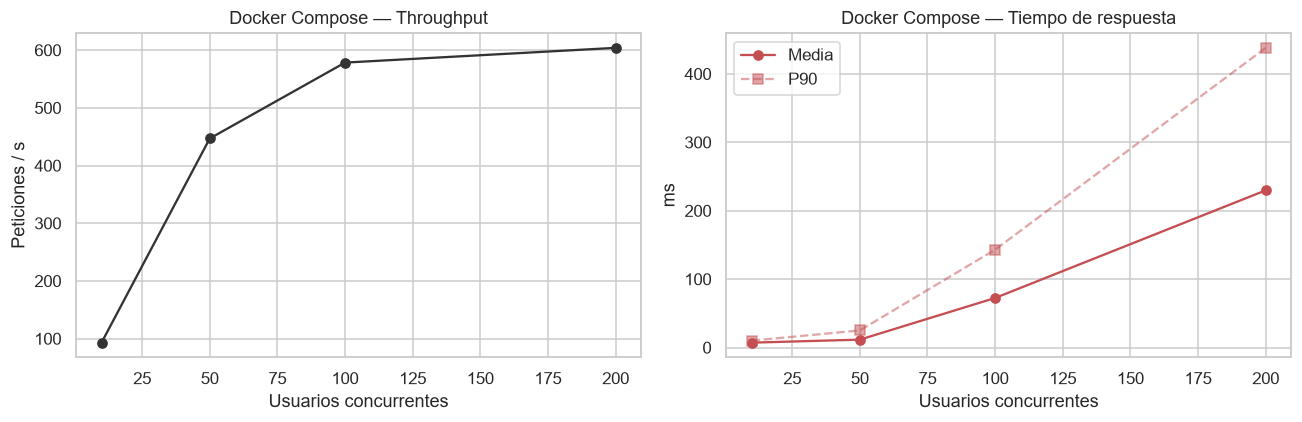

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(compose.usuarios, compose.throughput_rps, "o-", color="#333333")
ejes[0].set(title="Docker Compose — Throughput", xlabel="Usuarios concurrentes", ylabel="Peticiones / s")
ejes[1].plot(compose.usuarios, compose.tiempo_medio_ms, "o-", color="#C44E52", label="Media")
ejes[1].plot(compose.usuarios, compose.p90_ms, "s--", color="#C44E52", alpha=.5, label="P90")
ejes[1].set(title="Docker Compose — Tiempo de respuesta", xlabel="Usuarios concurrentes", ylabel="ms")
ejes[1].legend()
plt.tight_layout(); plt.show()

### 6.2 Impacto del número de réplicas (para cada cantidad de nodos)

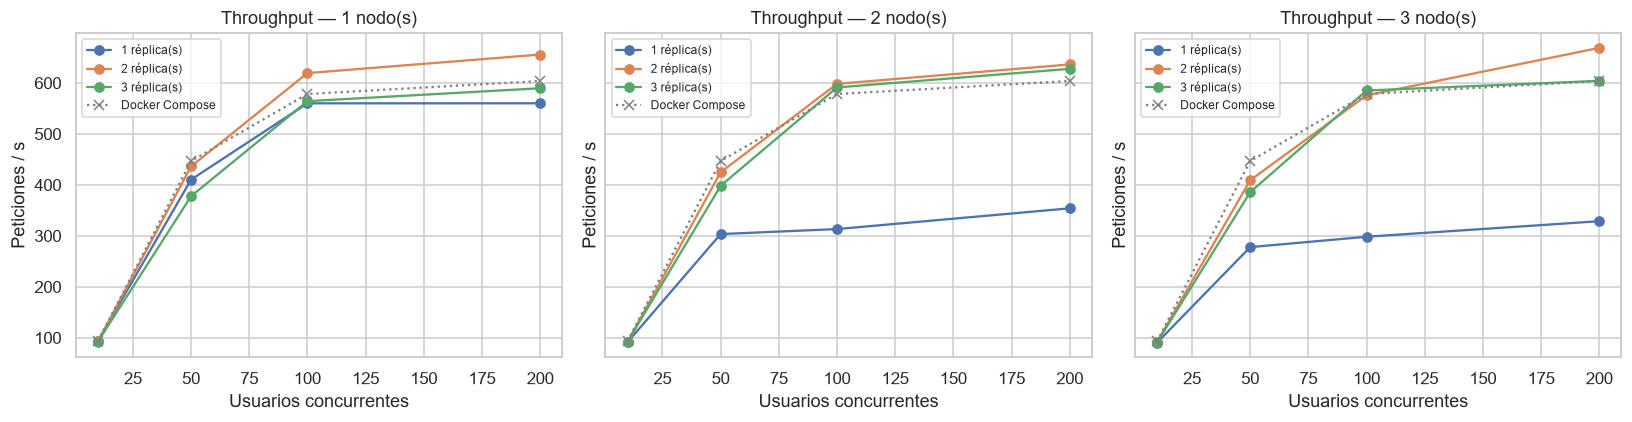

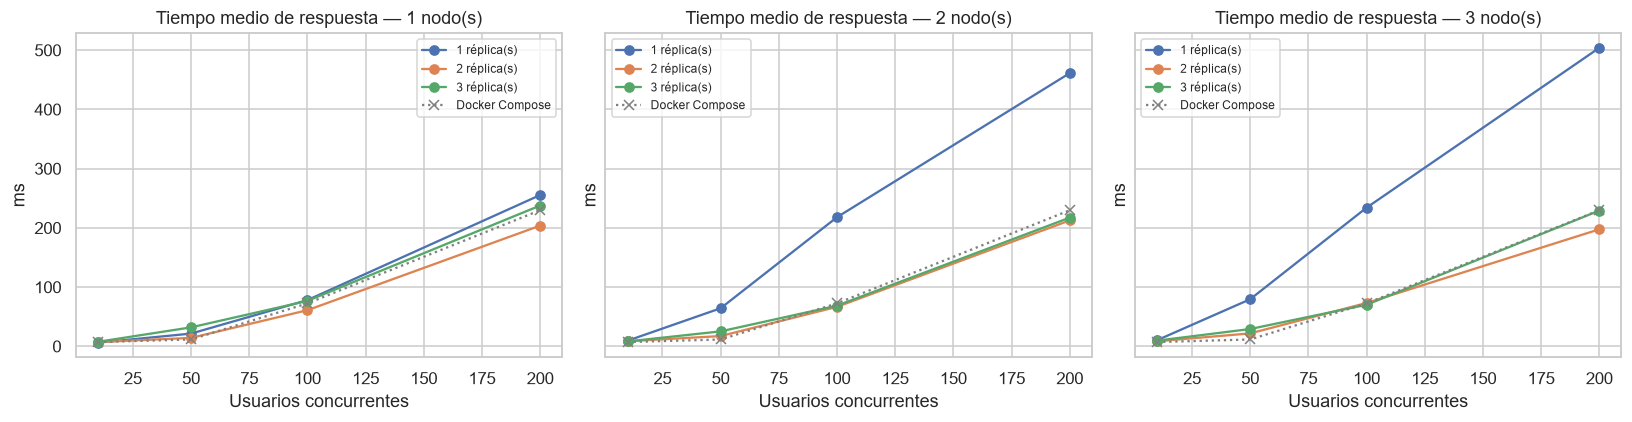

In [8]:
nodos_disp = sorted(k8s.nodos.unique())
for metrica, titulo, etiqueta in [("throughput_rps", "Throughput", "Peticiones / s"),
                                  ("tiempo_medio_ms", "Tiempo medio de respuesta", "ms")]:
    fig, ejes = plt.subplots(1, len(nodos_disp), figsize=(5 * len(nodos_disp), 4), sharey=True, squeeze=False)
    for eje, n in zip(ejes[0], nodos_disp):
        datos = k8s[k8s.nodos == n]
        for r, g in datos.groupby("replicas"):
            eje.plot(g.usuarios, g[metrica], "o-", color=PALETA_REPLICAS[r], label=f"{r} réplica(s)")
        eje.plot(compose.usuarios, compose[metrica], "x:", color="gray", label="Docker Compose")
        eje.set(title=f"{titulo} — {n} nodo(s)", xlabel="Usuarios concurrentes", ylabel=etiqueta)
        eje.legend(fontsize=8)
    plt.tight_layout(); plt.show()

### 6.3 Mapa de calor: nodos × réplicas con la carga máxima

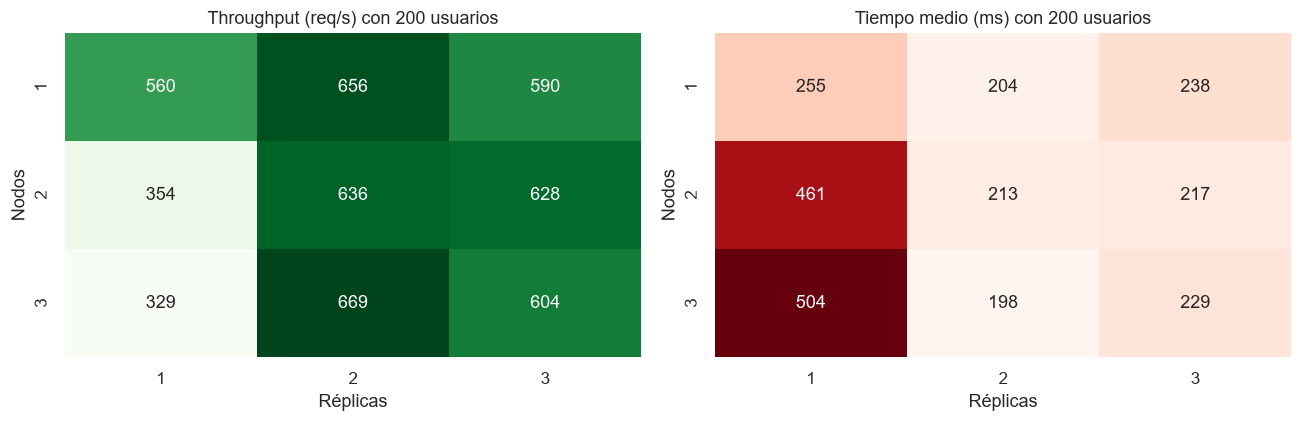

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
carga = k8s[k8s.usuarios == CARGA_MAX]
for eje, (metrica, titulo, cmap) in zip(ejes, [("throughput_rps", "Throughput (req/s)", "Greens"),
                                               ("tiempo_medio_ms", "Tiempo medio (ms)", "Reds")]):
    matriz = carga.pivot(index="nodos", columns="replicas", values=metrica)
    sns.heatmap(matriz, annot=True, fmt=".0f", cmap=cmap, ax=eje, cbar=False)
    eje.set(title=f"{titulo} con {CARGA_MAX} usuarios", xlabel="Réplicas", ylabel="Nodos")
plt.tight_layout(); plt.show()

### 6.4 Diferencia entre 1, 2 y 3 nodos (misma cantidad de réplicas)

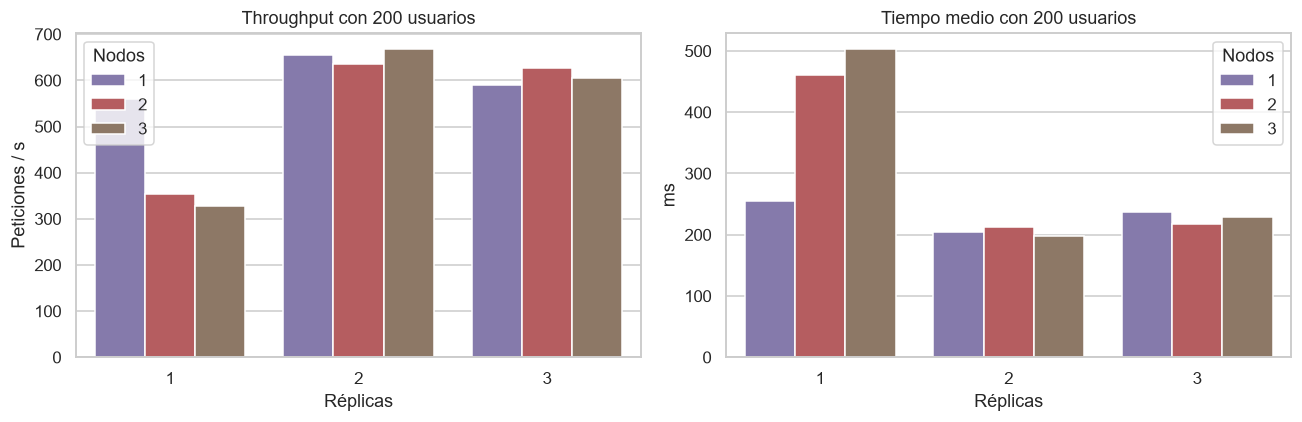

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=carga, x="replicas", y="throughput_rps", hue="nodos", palette=PALETA_NODOS, ax=ejes[0])
ejes[0].set(title=f"Throughput con {CARGA_MAX} usuarios", xlabel="Réplicas", ylabel="Peticiones / s")
sns.barplot(data=carga, x="replicas", y="tiempo_medio_ms", hue="nodos", palette=PALETA_NODOS, ax=ejes[1])
ejes[1].set(title=f"Tiempo medio con {CARGA_MAX} usuarios", xlabel="Réplicas", ylabel="ms")
for eje in ejes:
    eje.legend(title="Nodos")
plt.tight_layout(); plt.show()

### 6.5 Escalabilidad: *speedup* respecto a 1 réplica

El *speedup* indica cuántas veces aumenta el throughput al pasar de 1 réplica a *R* réplicas (con la carga máxima). El escalado ideal (lineal) sería 2× con 2 réplicas y 3× con 3 réplicas.

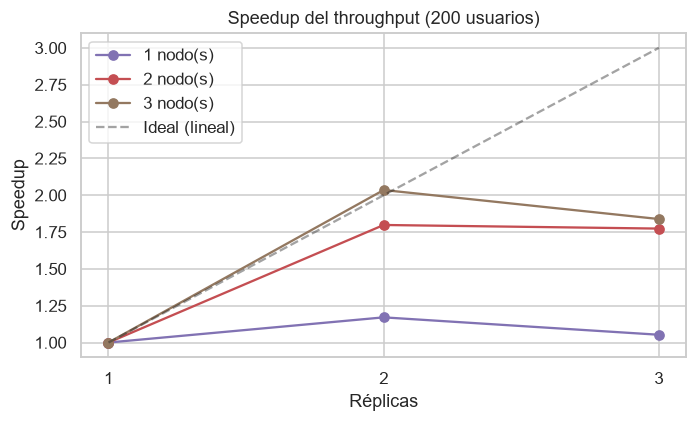

replicas,1,2,3
nodos,,,
1,1.0,1.17,1.05
2,1.0,1.80,1.77
3,1.0,2.04,1.84


In [11]:
base = carga[carga.replicas == 1].set_index("nodos")["throughput_rps"]
carga_sp = carga.assign(speedup=carga.apply(lambda f: f.throughput_rps / base[f.nodos], axis=1))
fig, eje = plt.subplots(figsize=(6.5, 4))
for n, g in carga_sp.groupby("nodos"):
    eje.plot(g.replicas, g.speedup, "o-", color=PALETA_NODOS[n], label=f"{n} nodo(s)")
eje.plot([1, 2, 3], [1, 2, 3], "k--", alpha=.4, label="Ideal (lineal)")
eje.set(title=f"Speedup del throughput ({CARGA_MAX} usuarios)", xlabel="Réplicas", ylabel="Speedup", xticks=[1, 2, 3])
eje.legend(); plt.tight_layout(); plt.show()
carga_sp.pivot(index="nodos", columns="replicas", values="speedup").round(2)

### 6.6 Docker Compose vs. Kubernetes con 1 nodo y 1 réplica (costo de la orquestación)

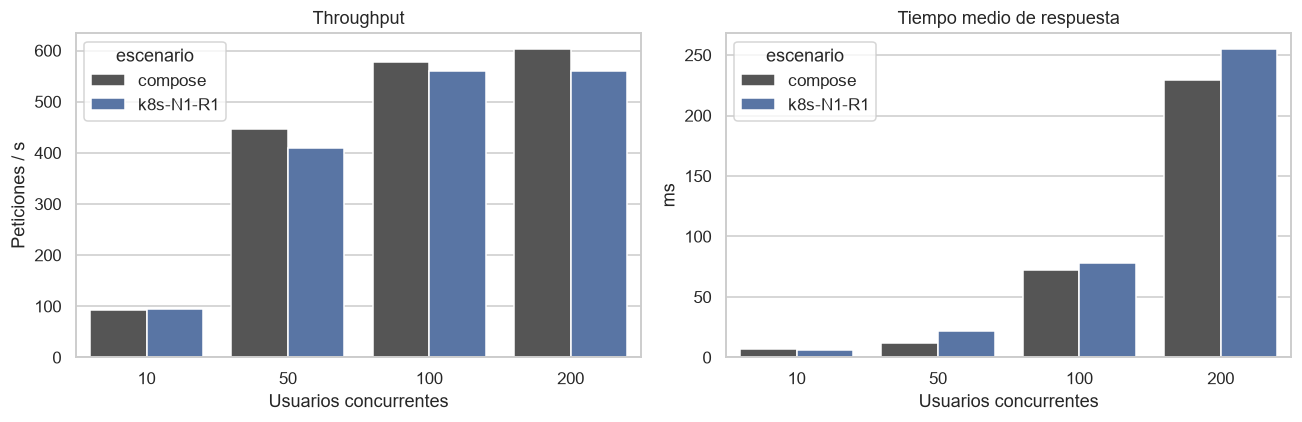

In [12]:
comp = resumen[(resumen.escenario == "compose") | (resumen.escenario == "k8s-N1-R1")]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=comp, x="usuarios", y="throughput_rps", hue="escenario", ax=ejes[0], palette=["#555555", "#4C72B0"])
ejes[0].set(title="Throughput", xlabel="Usuarios concurrentes", ylabel="Peticiones / s")
sns.barplot(data=comp, x="usuarios", y="tiempo_medio_ms", hue="escenario", ax=ejes[1], palette=["#555555", "#4C72B0"])
ejes[1].set(title="Tiempo medio de respuesta", xlabel="Usuarios concurrentes", ylabel="ms")
plt.tight_layout(); plt.show()

### 6.7 Tiempo de respuesta por endpoint (identificación de cuellos de botella)

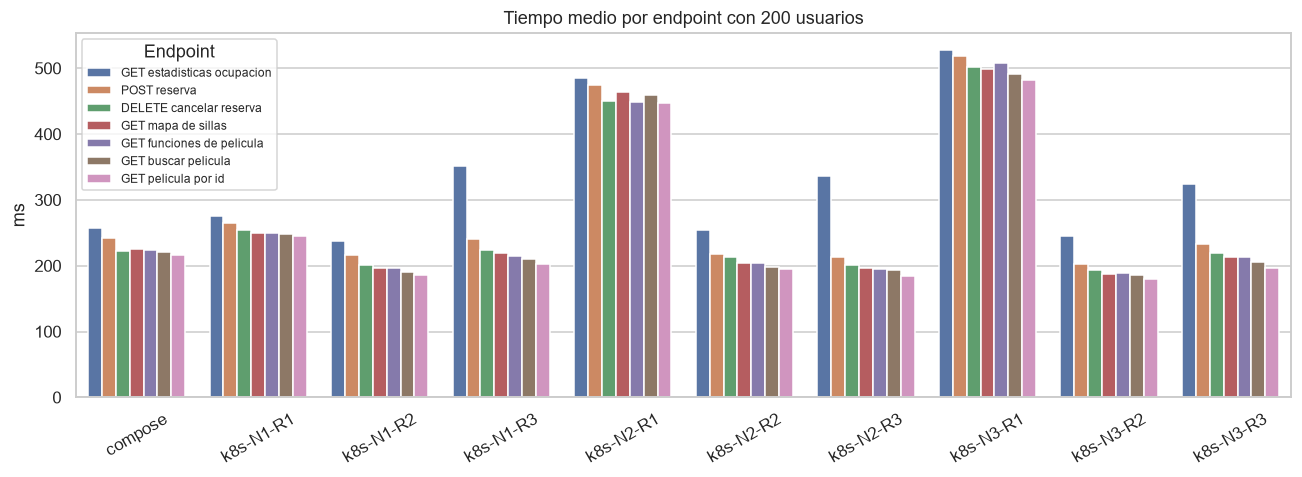

In [13]:
ep = endpoints[endpoints.usuarios == CARGA_MAX]
orden = ep.groupby("label")["elapsed"].mean().sort_values(ascending=False).index
fig, eje = plt.subplots(figsize=(12, 4.5))
sns.barplot(data=ep, x="escenario", y="elapsed", hue="label", hue_order=orden, ax=eje)
eje.set(title=f"Tiempo medio por endpoint con {CARGA_MAX} usuarios", xlabel="", ylabel="ms")
eje.tick_params(axis="x", rotation=30)
eje.legend(fontsize=8, title="Endpoint")
plt.tight_layout(); plt.show()

### 6.8 Tasa de errores

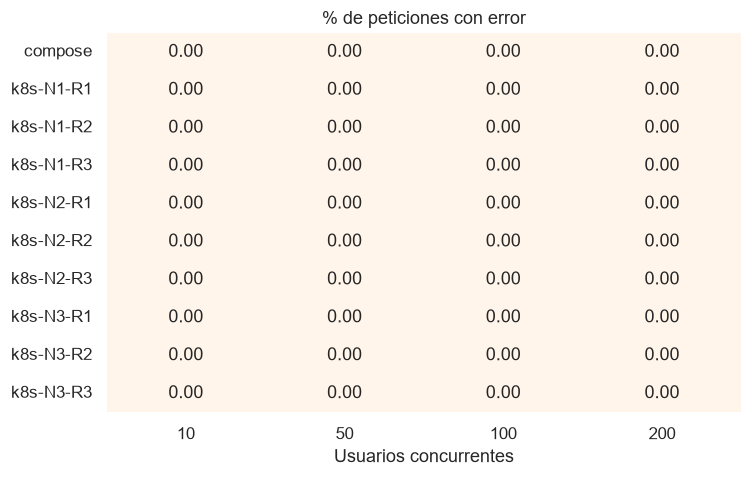

In [14]:
errores = resumen.pivot_table(index="escenario", columns="usuarios", values="error_pct")
fig, eje = plt.subplots(figsize=(7, 4.5))
sns.heatmap(errores, annot=True, fmt=".2f", cmap="Oranges", ax=eje, cbar=False)
eje.set(title="% de peticiones con error", xlabel="Usuarios concurrentes", ylabel="")
plt.tight_layout(); plt.show()

## 7. Análisis comparativo

La siguiente celda calcula automáticamente los hallazgos principales a partir de los datos cargados (si se reemplazan los resultados, los números se actualizan solos).

In [15]:
def fila(esc, u=CARGA_MAX):
    return resumen[(resumen.escenario == esc) & (resumen.usuarios == u)].iloc[0]

mejor = carga.loc[carga.throughput_rps.idxmax()]
peor = carga.loc[carga.throughput_rps.idxmin()]
c = fila("compose")
print(f"Con {CARGA_MAX} usuarios concurrentes:")
print(f"  * Docker Compose: {c.throughput_rps:.0f} req/s, {c.tiempo_medio_ms:.0f} ms de tiempo medio.")
print(f"  * Mejor escenario K8s: {mejor.escenario} -> {mejor.throughput_rps:.0f} req/s, {mejor.tiempo_medio_ms:.0f} ms "
      f"({mejor.throughput_rps / c.throughput_rps:.2f}x el throughput de Compose).")
print(f"  * Peor escenario K8s:  {peor.escenario} -> {peor.throughput_rps:.0f} req/s, {peor.tiempo_medio_ms:.0f} ms.")
for n in sorted(carga.nodos.unique()):
    g = carga[carga.nodos == n].set_index("replicas")
    if {1, 3} <= set(g.index):
        print(f"  * {n} nodo(s): de 1 a 3 réplicas el throughput cambia {100 * (g.loc[3].throughput_rps / g.loc[1].throughput_rps - 1):+.0f}% "
              f"y el tiempo medio {100 * (g.loc[3].tiempo_medio_ms / g.loc[1].tiempo_medio_ms - 1):+.0f}%.")
lento = ep.groupby("label")["elapsed"].mean().idxmax()
print(f"  * Endpoint más costoso: '{lento}'.")

Con 200 usuarios concurrentes:
  * Docker Compose: 604 req/s, 230 ms de tiempo medio.
  * Mejor escenario K8s: k8s-N3-R2 -> 669 req/s, 198 ms (1.11x el throughput de Compose).
  * Peor escenario K8s:  k8s-N3-R1 -> 329 req/s, 504 ms.
  * 1 nodo(s): de 1 a 3 réplicas el throughput cambia +5% y el tiempo medio -7%.
  * 2 nodo(s): de 1 a 3 réplicas el throughput cambia +77% y el tiempo medio -53%.
  * 3 nodo(s): de 1 a 3 réplicas el throughput cambia +84% y el tiempo medio -55%.
  * Endpoint más costoso: 'GET estadisticas ocupacion'.


## 8. Discusión de resultados

### 8.1 Con carga baja (10 y 50 usuarios) el despliegue casi no importa
Con 10 usuarios todos los escenarios atienden **≈ 90–94 req/s** con tiempos medios de **6–10 ms**. Coincide con la **Ley de Little**: cada usuario hace una petición cada ≈ 107 ms (100 ms de pausa + ≈ 7 ms de respuesta), así que 10 usuarios generan ≈ 93 req/s. Con 50 usuarios la mayoría de escenarios está entre **≈ 375 y 447 req/s**; la excepción son los escenarios con 1 réplica en un nodo trabajador (ver 8.5).

### 8.2 La aplicación se satura alrededor de 600 req/s
El techo teórico con 200 usuarios y 100 ms de pausa es ≈ 1.900 req/s, pero **ningún escenario superó 670 req/s**. Con Docker Compose el throughput pasa de 578 req/s (100 usuarios) a solo **604 req/s** (200 usuarios), mientras el tiempo medio se triplica (72 → **230 ms**, P90 de 438 ms). Es el comportamiento típico de un sistema saturado: las peticiones hacen cola y la espera crece, pero no se atienden más por segundo.

### 8.3 Más réplicas mejoran poco: el cuello de botella es `vm-app-1`
Con 1 nodo y 200 usuarios: 1 réplica → **560 req/s / 255 ms**; 2 réplicas → **656 req/s / 204 ms** (+17 %); 3 réplicas → **590 req/s / 238 ms**. Una segunda réplica ayuda algo, pero muy lejos de duplicar la capacidad, porque el recurso escaso no es la CPU de la réplica sino **los 2 vCPU de `vm-app-1`**. Esa VM aloja a la vez PostgreSQL, el plano de control de K3s, el punto de entrada NodePort (kube-proxy) y las réplicas que caen en ella. Además, las 4 VMs (8 vCPU) comparten los 8 hilos físicos del portátil.

### 8.4 La tercera réplica empeora los resultados
En los tres tamaños de clúster, 3 réplicas rindieron **menos que 2**: 590 frente a 656 req/s con 1 nodo, 628 frente a 636 con 2 nodos y 604 frente a 669 con 3 nodos. La consulta pesada `/api/estadisticas/ocupacion` pasa de ≈ 240–255 ms con 2 réplicas a **≈ 320–350 ms con 3**. Cada réplica abre su propio pool de conexiones, así que con 3 réplicas hay más consultas simultáneas contra **una sola instancia de PostgreSQL** que compite por la CPU del master. Escalar la API solo ayuda mientras la API sea el cuello de botella; aquí lo es la base de datos y la máquina que la aloja.

### 8.5 Uno, dos y tres nodos: dónde cae el pod importa más que cuántos nodos hay
* **Con 1 réplica, más nodos empeoró mucho:** con 2 nodos el pod quedó en `vm-app-2` y con 3 nodos en `vm-app-3` (ver `pods.txt`). El throughput bajó a **354 y 329 req/s** (−37 % y −41 % frente a 560 req/s con 1 nodo), y el tiempo medio subió a **461 y 504 ms**. Ya con 50 usuarios esos escenarios se saturan (≈ 280–300 req/s). La causa es la red: cada petición entra por el NodePort de `vm-app-1`, kube-proxy la reenvía por la red *overlay* (Flannel VXLAN) al nodo trabajador, y las varias consultas SQL de cada petición vuelven a cruzar la red hasta PostgreSQL en `vm-app-1`. Esa latencia extra por viaje se multiplica por cada consulta.
* **Con 2 réplicas, 3 nodos dio el mejor resultado de todo el experimento:** **669 req/s y 198 ms** (`k8s-N3-R2`, una réplica en `vm-app-1` y otra en `vm-app-3`), frente a 656 con 1 nodo y 636 con 2 nodos. Las diferencias entre nodos con 2 y 3 réplicas son pequeñas (≤ 5 %), porque los nodos nuevos agregan vCPU virtuales pero no hardware físico nuevo.
* Kubernetes **repartió las réplicas como se esperaba**: con 3 réplicas y 3 nodos quedó 1 + 1 + 1, y con 3 réplicas y 2 nodos, 2 + 1.

Los *speedups* altos con 2 y 3 nodos (×1,8 a ×2,0 al pasar de 1 a 2 réplicas) son engañosos: se miden contra una réplica penalizada por estar en un nodo trabajador. Frente a la mejor línea base (`k8s-N1-R1`, 560 req/s) la mejora máxima es de **×1,19**.

### 8.6 Docker Compose frente a Kubernetes
Con la misma réplica y los mismos recursos, Docker Compose obtuvo **604 req/s y 230 ms**, frente a **560 req/s y 255 ms** de Kubernetes con 1 nodo: un **≈ 7 % menos de throughput y ≈ 11 % más de latencia**. Es el **costo de la orquestación**: el salto adicional del Service NodePort (iptables/kube-proxy) y el consumo del plano de control de K3s en la misma VM. El mejor escenario de Kubernetes (`k8s-N3-R2`) supera a Compose en solo un **11 %**.

### 8.7 Endpoints y regla de negocio
* Con poca carga, el endpoint más costoso es **`/api/estadisticas/ocupacion`** (10–15 ms frente a 3–6 ms de `GET película por id`), porque une 4 tablas y agrupa las 10.000 reservas. Con 200 usuarios **todos los endpoints tardan ≈ 180–280 ms** con 1 o 2 réplicas en el master (≈ 450–530 ms con la réplica en un trabajador). La cola de peticiones domina sobre el costo de cada consulta.
* El **8,7 %** de los 256.541 intentos de reserva recibió **409** (silla ocupada), y al terminar las pruebas **no había ninguna silla reservada dos veces** en la base de datos, ni siquiera con 3 réplicas atendiendo en paralelo. La restricción `UNIQUE (funcion_id, fila, numero)` garantiza la regla de negocio en un sistema distribuido.
* En las 40 pruebas (≈ 1,78 millones de peticiones) la tasa de error fue **0 %**.

## 9. Conclusiones

1. **El rendimiento lo limita la máquina que aloja la base de datos, no la API.** Todos los escenarios se saturaron entre 560 y 670 req/s con 200 usuarios, muy por debajo de las ≈ 1.900 req/s que podía generar JMeter.
2. **El escalado horizontal tuvo rendimientos muy bajos.** Pasar de 1 a 2 réplicas mejoró el throughput entre un 14 % y un 19 % frente a la mejor línea base, y la tercera réplica empeoró los resultados en todos los casos por la contención en PostgreSQL. Antes de agregar réplicas hay que identificar el cuello de botella.
3. **La ubicación de los pods importa.** Una única réplica en un nodo trabajador perdió ≈ 40 % de throughput y duplicó la latencia, por el doble viaje por la red (entrada por el master y consultas a la base de datos en el master).
4. **Agregar nodos solo sirve si agrega recursos reales.** Los nodos 2 y 3 comparten el mismo hardware físico, y el mejor escenario (3 nodos, 2 réplicas) superó apenas en un 2 % a 1 nodo con 2 réplicas.
5. **Kubernetes cuesta ≈ 7 % frente a Docker Compose** con la misma réplica. A cambio permite escalar con un comando, reparte las réplicas entre nodos y reinicia pods caídos.
6. **La consistencia se mantuvo**: 0 % de errores y ninguna silla vendida dos veces, con varias réplicas escribiendo en paralelo.

## 10. Recomendaciones

* **Separar PostgreSQL de los nodos de la API** (un nodo o servicio gestionado propio), para que la base de datos no compita por CPU con el plano de control y las réplicas.
* **Usar 2 réplicas para esta carga:** dieron el mejor resultado en todos los tamaños de clúster, y una tercera solo se justifica si la base de datos escala o recibe más recursos.
* **Repartir la entrada de tráfico** entre todos los nodos (balanceador externo o Ingress) y **preferir que las réplicas estén cerca de la base de datos** (afinidad de pods), para evitar el doble salto de red.
* **Cachear las estadísticas de ocupación** (unos segundos en memoria o con Redis): es la consulta más costosa y la que más empeora con más réplicas.
* **Ajustar el pool de conexiones** (`DB_POOL`) según el número de réplicas, para no saturar PostgreSQL con conexiones simultáneas.
* Como siguiente paso, un **Horizontal Pod Autoscaler** podría ajustar las réplicas según la carga.

## 11. Limitaciones

* Las 4 VMs corren en **un mismo portátil** (8 hilos, 15 GB de RAM): comparten CPU física, y agregar un nodo no agrega hardware real. Los valores absolutos serían mayores en VMs de nube independientes.
* Por falta de memoria, `vm-app-2` y `vm-app-3` tuvieron **2 GB** en lugar de los 3 GB de `vm-app-1`, y `vm-jmeter` tuvo 2 GB (JMeter con 1 GB de *heap*).
* Cada configuración se midió **una sola vez** (120 s por nivel). Los escenarios `k8s-N1-R2` y `k8s-N1-R3` se repitieron porque el equipo entró en suspensión durante el primer intento. Para mayor rigor se recomienda repetir cada prueba 3 veces y reportar promedio y desviación.
* La pausa fija de 100 ms limita la carga máxima que pueden generar 200 usuarios (≈ 1.900 req/s), aunque en estas pruebas ese límite no se alcanzó.